# Part 3: The data you need: treated, control and the start date

*Series: Who Will Stay Because of Us? Uplift Modelling and Causal Inference for Client Attrition*

Act 1 used the true uplift, which only a synthetic bank can show. From here on we estimate it from data, the way a real bank would. Before any model, the data has to be set up correctly, and most uplift projects go wrong right here.

**In this notebook**

1. Why the control group must come from flagged clients.
2. Why clients who got a *different* intervention cannot be controls.
3. The start date: features from before it, outcomes from after it.
4. The leakage trap that makes a model look perfect and fail in practice.
5. Splitting into train and test **within** each group.

We stay in the clean world: `assignment="random"`, so pricing went to random flagged clients.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

from uplift_series import (FEATURES, LEAKY_COLUMNS, SERIES_SEED, analysis_pool,
                           generate_bank, naive_uplift, true_average_uplift)
from uplift_series import plotting as P
from uplift_series.modeling import DEFAULT_XGB_PARAMS, split_pool

P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)

df = generate_bank(assignment="random", seed=SERIES_SEED)
df.groupby(["flagged", "treatment"]).size().rename("clients").to_frame()

clients
flagged treatment           
0       none           34000
1       none            4000
        pricing         1000
        service_fix     1000

## 1. Treated and control

Uplift is a difference between two worlds: what happens **with** pricing and what happens **without** it. No client lives in both, so we compare two groups:

- **Treated:** clients who received a pricing negotiation.
- **Control:** comparable clients who received **nothing**.

Choosing the control group sounds trivial. It is not. Below are three choices an analyst might reasonably make.

In [2]:
treated = df[df["treatment"] == "pricing"]

def effect(control: pd.DataFrame) -> float:
    """Control churn minus treated churn."""
    return control["churned_6m"].mean() - treated["churned_6m"].mean()

choices = {
    "All clients with no pricing": df[df["treatment"] != "pricing"],
    "Flagged clients, incl. service fix": df[(df["flagged"] == 1) & (df["treatment"] != "pricing")],
    "Flagged clients with no action": df[(df["flagged"] == 1) & (df["treatment"] == "none")],
}
truth = true_average_uplift(analysis_pool(df))

table = pd.DataFrame({
    "control clients": {k: len(v) for k, v in choices.items()},
    "control churn": {k: v["churned_6m"].mean() for k, v in choices.items()},
    "estimated effect (pts)": {k: 100 * effect(v) for k, v in choices.items()},
})
print(f"Treated churn: {treated['churned_6m'].mean():.1%}   True effect: {100 * truth:.1f} points")
table

Treated churn: 16.0%   True effect: 7.7 points


,control clients,control churn,estimated effect (pts)
All clients with no pricing,39000,0.073,-8.710
"Flagged clients, incl. service fix",5000,0.217,5.700
Flagged clients with no action,4000,0.236,7.625


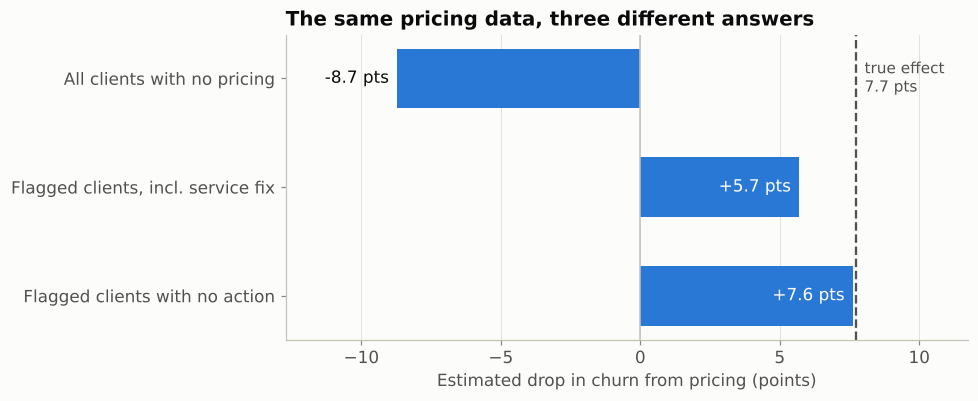

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
names = list(table.index)[::-1]
vals = table.loc[names, "estimated effect (pts)"]
bars = ax.barh(names, vals, color=P.BLUE, height=0.55)
ax.axvline(0, color=P.BASELINE, linewidth=1)
ax.axvline(100 * truth, color=P.INK_SECONDARY, linestyle="--", linewidth=1.5)
ax.text(100 * truth + 0.3, 2, f"true effect\n{100 * truth:.1f} pts", va="center",
        color=P.INK_SECONDARY, fontsize=10)
for b, v in zip(bars, vals):
    y = b.get_y() + b.get_height() / 2
    if v >= 0:   # label inside the bar end, clear of the dashed line
        ax.text(v - 0.3, y, f"{v:+.1f} pts", va="center", ha="right", color="white", fontsize=11)
    else:
        ax.text(v - 0.3, y, f"{v:+.1f} pts", va="center", ha="right", color=P.INK, fontsize=11)
ax.set_xlim(min(vals.min(), 0) - 4, max(vals.max(), 100 * truth) + 4)
ax.set_xlabel("Estimated drop in churn from pricing (points)")
ax.grid(axis="y", visible=False)
ax.set_title("The same pricing data, three different answers")
P.save(fig, "03_control_choice")
plt.show()

Same treated clients, same outcomes, three very different conclusions:

- **All clients with no pricing:** pricing appears to *increase* churn. The control group is mostly safe clients who were never at risk, so the comparison is "risky clients who got pricing" versus "safe clients who got nothing". The gap is about risk, not pricing.
- **Flagged clients, including the service fix:** the right population, but some controls got a service fix, which also reduces churn. The control group looks healthier than "no action" really is, so pricing looks weaker than it is.
- **Flagged clients with no action:** comparable clients who received nothing. This is the only fair comparison, and it lands on the truth.

`analysis_pool()` applies exactly these two rules: flagged clients only, and pricing or no action only.

## 2. The start date

Every client needs a reference date:

- **Treated:** the date of the pricing negotiation.
- **Control:** the date they were flagged.

Features are measured **before** this date. The outcome (did they leave?) is measured over a fixed window **after** it, six months here, the same for both groups.

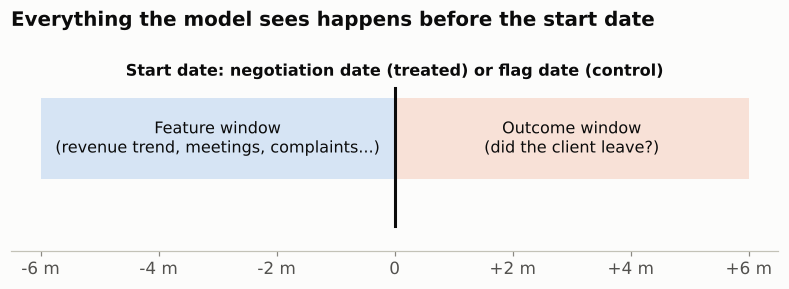

In [4]:
fig, ax = plt.subplots(figsize=(9, 2.4))
ax.axvspan(-6, 0, ymin=0.35, ymax=0.75, color=P.BLUE, alpha=0.18, linewidth=0)
ax.axvspan(0, 6, ymin=0.35, ymax=0.75, color=P.ORANGE, alpha=0.18, linewidth=0)
ax.plot([0, 0], [0.12, 0.8], color=P.INK, linewidth=2)
ax.text(-3, 0.55, "Feature window\n(revenue trend, meetings, complaints...)", ha="center", va="center",
        color=P.INK, fontsize=10.5)
ax.text(3, 0.55, "Outcome window\n(did the client leave?)", ha="center", va="center",
        color=P.INK, fontsize=10.5)
ax.text(0, 0.86, "Start date: negotiation date (treated) or flag date (control)", ha="center",
        color=P.INK, fontsize=10.5, fontweight="bold")
ax.set_xlim(-6.5, 6.5)
ax.set_ylim(0, 1)
ax.set_yticks([])
ax.set_xticks(range(-6, 7, 2), [f"{m:+d} m" if m else "0" for m in range(-6, 7, 2)])
ax.spines["left"].set_visible(False)
ax.grid(False)
ax.set_title("Everything the model sees happens before the start date", pad=14)
P.save(fig, "03_timeline")
plt.show()

## 3. The leakage trap

The data contains a column called `txn_change_after_start`: the change in transaction volume **after** the start date. It is a tempting feature, because clients who leave stop transacting. Watch what it does to an ordinary churn model.

In [5]:
train, test = train_test_split(df, test_size=0.3, stratify=df["churned_6m"], random_state=0)
auc = {}
for name, cols in {"Pre-start features only": FEATURES,
                   "Plus one post-start feature": FEATURES + LEAKY_COLUMNS}.items():
    model = xgb.XGBClassifier(**DEFAULT_XGB_PARAMS).fit(train[cols], train["churned_6m"])
    auc[name] = roc_auc_score(test["churned_6m"], model.predict_proba(test[cols])[:, 1])
pd.Series(auc, name="test ROC-AUC").to_frame()

,test ROC-AUC
Pre-start features only,0.766
Plus one post-start feature,0.996


Adding one post-start column takes the model from respectable to nearly perfect. But on the day an RM needs the list, that column does not exist yet: next month's transactions have not happened. The model would look brilliant in testing and be useless in production.

The same trap catches uplift models, and it is harder to spot there, because there is no single accuracy number to look suspicious. The rule is simple: **if a value could only be known after the start date, it cannot be a feature.** In this repo, `FEATURES` lists the safe columns and `LEAKY_COLUMNS` the unsafe one.

## 4. Split within each group

Finally, hold back 30% of clients for testing, so the uplift model can later be checked on clients it has never seen. The split is **stratified by treatment**, so both the training and test sets keep the same mix of treated and control clients. Validation in Part 5 needs both groups in every slice of the test set.

In [6]:
pool = analysis_pool(df)
train, test = split_pool(pool, test_size=0.3, seed=0)
pd.DataFrame({
    "train": train["treated"].value_counts().rename({1: "treated", 0: "control"}),
    "test": test["treated"].value_counts().rename({1: "treated", 0: "control"}),
})

,train,test
treated,,
control,2800,1200
treated,700,300


## Takeaways

- **Control = comparable clients who got nothing.** Start from flagged clients, and exclude anyone who received a different intervention.
- **Every client gets a start date.** Features come from before it; the outcome from a fixed window after it, the same for both groups.
- **One post-start feature can make a model look perfect and be useless.** Check every column against the start date.
- **Split within each group**, so the test set holds both treated and control clients in the same proportions.

**Next, Part 4:** with the data in shape, we build the first uplift model: two XGBoost models, one for each parallel world.